# Web Scraping – Aires acondicionados en Éxito.com
*Selenium (renderiza el JavaScript) + BeautifulSoup (parseo del HTML) + pandas (para análisis).*


## S30 - Evidencia de aprendizaje 1. Análisis y herramientas de extracción de datos

**CURSO PROGRAMACIÓN PARA ANÁLISIS DE DATOS - PREICA2602B020048**

integrantes del grupo:

Lady Laura Olmos

Selenis Lorena Ramos Guardo

Maria Isabel Atencia

Jorge Andrés Hernandez




In [ ]:
!pip install -q --upgrade pip
!pip install -q selenium beautifulsoup4 lxml pandas matplotlib seaborn

## `1.` CONFIGURACIÓN DEL NAVEGADOR

In [ ]:
import os, re, time, random
import pandas as pd
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.common.exceptions import TimeoutException

# Instala Chrome de manera silenciosa si no está disponible
if not os.path.exists('/usr/bin/google-chrome'):
    print('Instalando Google Chrome...')
    os.system('wget -q https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb')
    os.system('apt-get install -y ./google-chrome-stable_current_amd64.deb > /dev/null 2>&1')
    os.system('rm -f google-chrome-stable_current_amd64.deb')

def crear_driver():
    opts = Options()
    opts.add_argument('--headless')
    opts.add_argument('--no-sandbox')
    opts.add_argument('--disable-dev-shm-usage')
    opts.add_argument('--disable-gpu')
    opts.add_argument('--disable-extensions')
    opts.add_argument('window-size=1920x1080')
    opts.add_argument('user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36')
    return webdriver.Chrome(options=opts)

*`Nota`: se definió la importación del driver. Se instaló directamente `selenium` y los parsers para evitar fallas a falta de librerías.*



## `2.` EXTRACCIÓN DE LOS DATOS DE CADA TARJETA

*(BeautifulSoup)*


In [ ]:
def extraer_producto(art):
    """Extrae de forma óptima los datos de un elemento <article> de BeautifulSoup."""
    texto = art.get_text(" ", strip=True)

    # --- Extracción optimizada de Nombre y URL ---
    nombre, url = "", ""
    enlace = art.find("a", href=lambda h: h and "/p" in h)
    if enlace:
        url = enlace["href"]
        nombre = enlace.get_text(strip=True) or enlace.get("title") or enlace.get("aria-label") or ""

    if not nombre:
        img = art.find("img", alt=True)
        if img:
            nombre = img["alt"].strip()

    if not nombre:
        m = re.search(r"(Aire\s.+?\d{4,5}\s*Btu\S*(?:\s+\d+\s*V)?(?:\s+[A-Z0-9\-]{5,})?)", texto, re.I)
        nombre = m.group(1) if m else "Producto sin nombre"

    if url.startswith("/"):
        url = "https://www.exito.com" + url

    # --- Precios y Atributos ---
    precios = [int(p.replace(".", "")) for p in re.findall(r"\$\s*([\d\.]{4,})", texto)]
    m_desc = re.search(r"(\d{1,2})\s*%", texto)
    m_vend = re.search(r"Vendido por:\s*(.+?)(?=\s+\d\.\d\s+\(|\s+\(\d+\s*opini|\s+Agregar|$)", texto)
    m_rat  = re.search(r"(\d\.\d)\s*\((\d+)\s*opini", texto)

    return {
        "nombre": nombre,
        "url": url,
        "patrocinado": "Patrocinado" in texto,
        "precio_actual": min(precios) if precios else None,
        "precio_anterior": max(precios) if len(precios) > 1 else None,
        "descuento_pct": int(m_desc.group(1)) if m_desc else None,
        "vendedor": m_vend.group(1).strip() if m_vend else "Éxito",
        "calificacion": float(m_rat.group(1)) if m_rat else None,
        "n_opiniones": int(m_rat.group(2)) if m_rat else None,
        "detalles": texto
    }

*`Nota`: Tras la revisión se notaron redundancias al detectar marcas y en el parseo de datos.*

## `3.` RECORRIDO DE TODAS LAS PAGINAS

Se visita `?page=1`, `?page=2`, ... `?page=16`, y se detiene cuando una página ya no trae productos nuevos.

In [ ]:
BASE_URL = "https://www.exito.com/electrodomesticos/climatizacion/aires-acondicionados"
MAX_PAGINAS = 40

def scroll_hasta_el_final(driver, pausa=1.2, max_intentos=10):
    """Realiza scroll optimizado descendente para asegurar la carga del lazy loading."""
    previo = -1
    for _ in range(max_intentos):
        driver.execute_script("window.scrollBy(0, 1000);")
        time.sleep(pausa)
        actual = len(driver.find_elements(By.TAG_NAME, "article"))
        if actual == previo:
            break
        previo = actual

def scrapear_todo():
    driver = crear_driver()
    wait = WebDriverWait(driver, 15)
    productos, urls_vistas = [], set()
    try:
        for pagina in range(1, MAX_PAGINAS + 1):
            driver.get(f"{BASE_URL}?page={pagina}")
            try:
                wait.until(EC.presence_of_element_located((By.TAG_NAME, "article")))
            except TimeoutException:
                print(f"Página {pagina}: Sin productos identificados. Finalizando scraping.")
                break

            scroll_hasta_el_final(driver)
            soup = BeautifulSoup(driver.page_source, "lxml")
            tarjetas = soup.find_all("article")

            nuevos = 0
            for art in tarjetas:
                p = extraer_producto(art)
                if p["url"] and p["url"] not in urls_vistas:
                    urls_vistas.add(p["url"])
                    p["pagina"] = pagina
                    productos.append(p)
                    nuevos += 1

            print(f"Página {pagina}: {len(tarjetas)} tarjetas detectadas, {nuevos} productos nuevos.")
            if nuevos == 0:
                break
            time.sleep(random.uniform(1.5, 3.0))
    finally:
        driver.quit()
    return pd.DataFrame(productos)

df = scrapear_todo()
df.to_csv("aires_acondicionados_exito.csv", index=False, encoding="utf-8-sig")
print(f"\nScraping completado. Total de productos únicos guardados: {len(df)}")

Página 1: 16 tarjetas detectadas, 16 productos nuevos.
Página 2: 13 tarjetas detectadas, 13 productos nuevos.
Página 3: 16 tarjetas detectadas, 16 productos nuevos.
Página 4: 13 tarjetas detectadas, 13 productos nuevos.
Página 5: 13 tarjetas detectadas, 13 productos nuevos.
Página 6: 13 tarjetas detectadas, 13 productos nuevos.
Página 7: 12 tarjetas detectadas, 12 productos nuevos.
Página 8: 13 tarjetas detectadas, 13 productos nuevos.
Página 9: 11 tarjetas detectadas, 11 productos nuevos.
Página 10: 11 tarjetas detectadas, 11 productos nuevos.
Página 11: 12 tarjetas detectadas, 12 productos nuevos.
Página 12: 12 tarjetas detectadas, 12 productos nuevos.
Página 13: 12 tarjetas detectadas, 12 productos nuevos.
Página 14: 14 tarjetas detectadas, 14 productos nuevos.
Página 15: 9 tarjetas detectadas, 9 productos nuevos.
Página 16: Sin productos identificados. Finalizando scraping.

Scraping completado. Total de productos únicos guardados: 190


In [ ]:
# Visualización de registros de forma aleatoria
df.sample(15)

,nombre,url,patrocinado,precio_actual,precio_anterior,descuento_pct,vendedor,calificacion,n_opiniones,detalles,pagina,btu,marca,tipo,portatil,descuento_calc
129,Ventilador Difusor Aire Acondicionado Portátil...,https://www.exito.com/ventilador-difusor-aire-...,False,186959,186960.0,NaN,Evolutech tbh Ver 1 oferta adicional,NaN,NaN,Producto genérico Ventilador Difusor Aire Acon...,10,NaN,Generico,Otro,True,0.0
13,Aire Acondicionado. Inverter FINLANDEK 12000 B...,https://www.exito.com/aire-acondicion-12000btu...,False,1449855,2200900.0,34.0,Exito,5.0,2.0,Aire Acondicionado. Inverter FINLANDEK 12000 B...,1,12000.0,Finlandek,Inverter,False,34.1
183,Combo Mertec Saduchera Gril Molino De Café Y G...,https://www.exito.com/combo-mertec-saduchera-g...,False,158900,227900.0,30.0,Dale clic shop,NaN,NaN,Combo Mertec Saduchera Gril Molino De Café Y G...,15,NaN,Mertec,Otro,False,30.3
3,Aire acondicionado Convencional FINLANDEK 9000...,https://www.exito.com/aire-acondicionado-conve...,False,972405,1349900.0,27.0,Exito,NaN,NaN,Aire acondicionado Convencional FINLANDEK 9000...,1,9000.0,Finlandek,Convencional,False,28.0
61,Aire Acondicionado Portátil Enfriador De Uso P...,https://www.exito.com/aire-acondicionado-porta...,False,30474,NaN,NaN,3 tiendas Ver 1 oferta adicional,NaN,NaN,Producto genérico Aire Acondicionado Portátil ...,5,NaN,Generico,Otro,True,NaN
182,"Ventilador Pedestal Home Elements 18"" Pulgadas...",https://www.exito.com/ventilador-pedestal-home...,False,209900,399900.0,47.0,Oportunidades,NaN,NaN,"Ventilador Pedestal Home Elements 18"" Pulgadas...",15,NaN,Home Elements,Otro,False,47.5
28,Aire Acondicionado Portátil Inteligente Tcl 80...,https://www.exito.com/aire-acondicionado-porta...,False,3409550,3921550.0,13.0,Simaro co,NaN,NaN,Aire Acondicionado Portátil Inteligente Tcl 80...,2,8000.0,Tcl,Otro,True,13.1
93,Deflector Para Aire Acondicionado Blanco Da100b,https://www.exito.com/deflector-para-aire-acon...,False,22900,34000.0,32.0,Electrojaponesa,NaN,NaN,Producto genérico Deflector Para Aire Acondici...,7,NaN,Generico,Otro,False,32.6
121,Aire Acondicionado 350 Pies Cúbicos Insignia P...,https://www.exito.com/aire-acondicionado-350-p...,False,3386550,3895550.0,13.0,Simaro co,NaN,NaN,Aire Acondicionado 350 Pies Cúbicos Insignia P...,10,NaN,Insignia,Otro,True,13.1
24,Aire Acondicionado. Inverter FINLANDEK 12000 B...,https://www.exito.com/aire-acondicion-12000btu...,False,1269285,3412300.0,62.0,Exito,3.0,4.0,Aire Acondicionado. Inverter FINLANDEK 12000 B...,2,12000.0,Finlandek,Inverter,False,62.8


## `4.` VERIFICACIÓN


*Se asegura y revisa que no haya nombres o precios nulos.*

In [ ]:
print(df.groupby("pagina").size())
print("\nNulos por columna:\n", df[["nombre", "precio_actual"]].isna().sum())


pagina
1     16
2     13
3     16
4     13
5     13
6     13
7     12
8     13
9     11
10    11
11    12
12    12
13    12
14    14
15     9
dtype: int64

Nulos por columna:
 nombre           0
precio_actual    0
dtype: int64


## `5. `LIMPIEZA

 * *AÑADIDURA DE VARIABLES NUEVAS*

In [ ]:
import pandas as pd
import re

# Cargar los datos reales obtenidos del scraper
try:
    df = pd.read_csv('aires_acondicionados_exito.csv')
except FileNotFoundError:
    raise FileNotFoundError("El archivo 'aires_acondicionados_exito.csv' no existe. Asegúrate de ejecutar la celda del scraper para generar los datos reales antes de continuar.")

# Limpieza rápida y eficiente de duplicados y nulos esenciales
df = df.drop_duplicates(subset='url').dropna(subset=['precio_actual']).copy()

# Extracción optimizada de capacidad (BTU) numérico directo
df['btu'] = df['nombre'].str.extract(r'(\d{4,5})\s*Btu', flags=re.I)[0].astype(float)

# Lista compactada de marcas para búsqueda directa
MARCAS = ['LG', 'Samsung', 'Mabe', 'Electrolux', 'Midea', 'Haceb', 'Whirlpool', 'Challenger', 'Kalley', 'Hyundai', 'Finlandek', 'Hisense', 'TCL', 'Carrier', 'York', 'Gree']

def detectar_marca(fila):
    nombre, texto = str(fila['nombre']), str(fila['detalles'])
    if nombre in texto:
        despues = texto.split(nombre, 1)[1].strip()
        m = re.match(r'([A-Za-zÁÉÍÓÚÑ0-9\+\.& ]{2,25}?)(?=\s+-\s|\s+\d{1,2}\s*%|\s+\$|$)', despues)
        if m and m.group(1).strip() and m.group(1).strip().lower() not in ('producto genérico', 'producto generico'):
            return m.group(1).strip().title()
    for m in MARCAS:
        if re.search(rf'\b{re.escape(m)}\b', nombre, re.I):
            return m.upper() if len(m) <= 3 else m
    return 'Otra'

df['marca'] = df.apply(detectar_marca, axis=1)
df['tipo'] = df['nombre'].apply(lambda x: 'Inverter' if 'inverter' in str(x).lower() else ('Convencional' if any(k in str(x).lower() for k in ['convencional', 'on/off', 'on-off']) else 'Otro'))
df['portatil'] = df['nombre'].str.contains('port[aá]til', case=False, regex=True)
df['descuento_calc'] = ((df['precio_anterior'] - df['precio_actual']) / df['precio_anterior'] * 100).round(1)

display(df[['nombre', 'marca', 'tipo', 'btu', 'precio_actual']].head(10))

,nombre,marca,tipo,btu,precio_actual
0,Aire Acondicionado Inverter HYUNDAI 12000 Btu ...,Hyundai,Inverter,12000.0,1286343
1,Aire Acondicionado Dual Inverter LG 9000 Btu 2...,.Sj1 Lg,Inverter,9000.0,1771000
2,Aire Acondicionado Dual Inverter LG 18000 Btu ...,.Sso Lg,Inverter,18000.0,2806000
3,Aire acondicionado Convencional FINLANDEK 9000...,Finlandek,Convencional,9000.0,972405
4,Aire Acondicionado Portatil Artic Air Ultra 2X...,Artic Air X 2,Otro,NaN,30619
5,Aire Acondicionado Convencional LG 12000 Btu 2...,Lg,Convencional,12000.0,1442000
6,Aire Acondicionado Dual Inverter LG 18000 Btu ...,.Ss1 Lg,Inverter,18000.0,3535000
7,Aire Acondicionado Dual Inverter LG 22000 Btu ...,.Sso Lg,Inverter,22000.0,3319000
8,Aire Acondicionado Convencional FINLANDEK 1200...,Finlandek,Convencional,12000.0,995695
9,Aire acondicionado Convencional HACEB 12000 Bt...,Haceb,Convencional,12000.0,1391874


In [ ]:
# Revisión de todas las columnas
df.head()


,nombre,url,patrocinado,precio_actual,precio_anterior,descuento_pct,vendedor,calificacion,n_opiniones,detalles,pagina,btu,marca,tipo,portatil,descuento_calc
0,Aire Acondicionado Inverter HYUNDAI 12000 Btu ...,https://www.exito.com/hy12k233iv-inverter-hyun...,False,1286343,1471200.0,12.0,Exito,NaN,NaN,Aire Acondicionado Inverter HYUNDAI 12000 Btu ...,1,12000.0,Hyundai,Inverter,False,12.6
1,Aire Acondicionado Dual Inverter LG 9000 Btu 2...,https://www.exito.com/aire-ac-win-inverter-900...,False,1771000,2394000.0,26.0,Exito,NaN,NaN,Aire Acondicionado Dual Inverter LG 9000 Btu 2...,1,9000.0,.Sj1 Lg,Inverter,False,26.0
2,Aire Acondicionado Dual Inverter LG 18000 Btu ...,https://www.exito.com/aire-acon-2en1-18000-btu...,False,2806000,4384700.0,36.0,Exito,NaN,NaN,Aire Acondicionado Dual Inverter LG 18000 Btu ...,1,18000.0,.Sso Lg,Inverter,False,36.0
3,Aire acondicionado Convencional FINLANDEK 9000...,https://www.exito.com/aire-acondicionado-conve...,False,972405,1349900.0,27.0,Exito,NaN,NaN,Aire acondicionado Convencional FINLANDEK 9000...,1,9000.0,Finlandek,Convencional,False,28.0
4,Aire Acondicionado Portatil Artic Air Ultra 2X...,https://www.exito.com/aire-acondicionado-porta...,False,30619,NaN,NaN,3 tiendas,5.0,1.0,Aire Acondicionado Portatil Artic Air Ultra 2X...,1,NaN,Artic Air X 2,Otro,True,NaN


## `6. `ANÁLISIS DESCRIPTIVO

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
pd.options.display.float_format = '{:,.0f}'.format

print("======= Precio actual (COP) =======")
print(df["precio_actual"].describe())

print("\n======= Por marca =======")
print(df.groupby("marca")["precio_actual"].agg(["count","mean","median","min","max"]).sort_values("count", ascending=False))

print("\n======= Por tipo =======")
print(df.groupby("tipo")["precio_actual"].agg(["count","mean","median"]))

print("\n======= Por capacidad (BTU) =======")
print(df.groupby("btu")["precio_actual"].agg(["count","mean"]))

print(f"\nProductos con descuento: {df['precio_anterior'].notna().mean()*100:.1f}%")
print(f"Productos patrocinados: {df['patrocinado'].mean()*100:.1f}%")

======= Precio actual (COP) =======
count          190
mean     1,340,899
std      1,777,724
min         22,900
25%        139,640
50%      1,020,298
75%      1,828,730
max     14,999,990
Name: precio_actual, dtype: float64

======= Por marca =======
                       count      mean    median      min       max
marca                                                              
Generico                  55 1,034,759   130,000    22900  14999990
Home Elements             14   242,971   249,900   171900    316900
Mabe                      14 1,793,626 1,635,187   879900   3134900
Finlandek                 10 1,412,095 1,399,878   972405   2305400
Midea                     10 2,063,394 1,229,900   227000   5519900
Hisense                    7 1,479,971 1,375,000  1239900   1950000
Mertec                     6   186,400   181,900   108400    304400
Haceb                      6 1,652,413 1,622,400  1391874   2069900
Challenger                 4 1,871,900 1,876,900  1269900   2463900
A

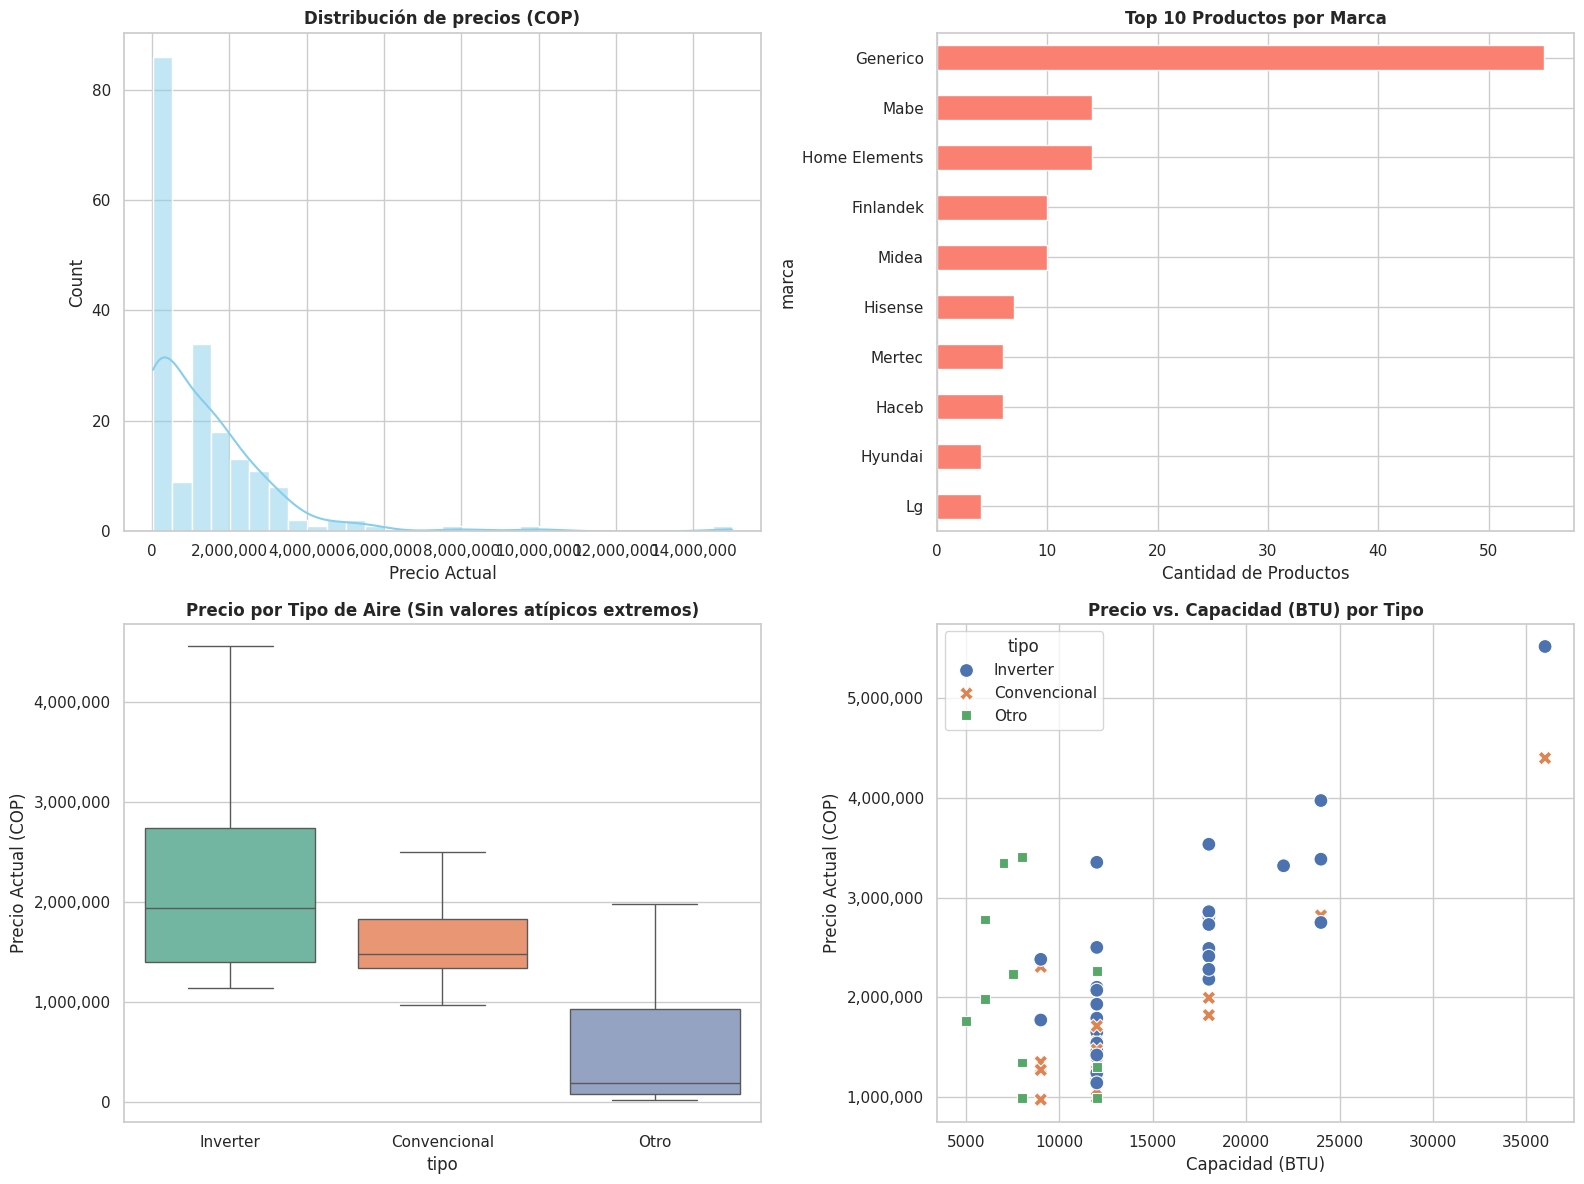

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo gráficos
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(2, 2, figsize=(16, 12))

# Distribución de precios (COP) (con escala mas clara)
sns.histplot(df["precio_actual"], bins=30, kde=True, ax=ax[0,0], color="skyblue")
ax[0,0].set_title("Distribución de precios (COP)", fontsize=12, fontweight='bold')
ax[0,0].set_xlabel("Precio Actual")
ax[0,0].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Productos por marca (Top 10 más comunes para evitar saturación)
top_marcas = df["marca"].value_counts().head(10)
df_top_marcas = df[df["marca"].isin(top_marcas.index)]

top_marcas.plot.barh(ax=ax[0,1], color="salmon")
ax[0,1].set_title("Top 10 Productos por Marca", fontsize=12, fontweight='bold')
ax[0,1].set_xlabel("Cantidad de Productos")
ax[0,1].invert_yaxis()

# Comparativa de Precios por tipo de aire
sns.boxplot(data=df, x="tipo", y="precio_actual", hue="tipo", ax=ax[1,0], palette="Set2", legend=False, showfliers=False)
ax[1,0].set_title("Precio por Tipo de Aire (Sin valores atípicos extremos)", fontsize=12, fontweight='bold')
ax[1,0].set_ylabel("Precio Actual (COP)")
ax[1,0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Precio vs. Capacidad (BTU) categorizado por Tipo de Aire
sns.scatterplot(data=df.dropna(subset=['btu']), x="btu", y="precio_actual", hue="tipo", style="tipo", s=100, ax=ax[1,1])
ax[1,1].set_title("Precio vs. Capacidad (BTU) por Tipo", fontsize=12, fontweight='bold')
ax[1,1].set_xlabel("Capacidad (BTU)")
ax[1,1].set_ylabel("Precio Actual (COP)")
ax[1,1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.tight_layout()
plt.savefig("analisis_aires.png", dpi=150)
plt.show()

In [ ]:
# Descargar el archivo CSV generado
from google.colab import files

nombre_archivo_csv = 'aires_acondicionados_exito.csv'
files.download(nombre_archivo_csv)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>